# WeatherNext forecast capacity factors vs. PECD / ERA5

PECD's own official capacity-factor product is good for two structural
reasons that have nothing to do with weather-forecast skill: (1) a
proprietary methodology built on real, per-turbine wind-farm data this
hub doesn't have access to, and (2) it is computed from ERA5
**reanalysis** -- essentially perfect, ex-post weather, not a forecast.
`forecast_capacity_factors_de` (`energy-data-hub`) instead uses
WeatherNext 3's actual day-ahead/multi-day **forecasts**, run through
this hub's own from-scratch replication methodology (GWA wind-speed bias
correction, hub-height extrapolation, per-plant turbine curves,
PECD-documented solar chain) -- so it is missing *both* of PECD's
advantages at once: neither PECD's own methodology, nor perfect
hindsight weather.

This page asks, step by step: how big is the gap against PECD overall:
how does that gap *look* over real time (not just as a summary number),
and how much of it is attributable to weather-forecast uncertainty
specifically (isolated by comparing against this hub's own ERA5-based
replication, same methodology, same real weather-observation basis)
rather than to the methodology difference against PECD.

**Known caveats carried over from the exploration that produced this
page (see the OpenSpec change `add-weathernext-forecast-capacity-
factors` and its own design notes for the fuller trail):**
- A forecast lead hour that happens to fall at night trivially gives
  zero solar capacity factor on *both* sides of any comparison -- not a
  bug, just means a single fixed lead hour is never a fair solar
  comparison point. Full RE's blend is dominated by wind at those hours.

**Everything this page reads is a materialized hub asset** -- no inline
CDS/BigQuery pulls, no inline weather-to-capacity-factor conversion.
PECD's `pecd_*_capacity_factors` assets now self-extend into the current
year (2015-2025 frozen + however much of this year CDS has published,
re-checked on every materialization -- see `edh.pecd.download_current_
year_capacity_factor_zip`), and the ERA5-fed comparison series comes
from `era5_capacity_factors_de` (same per-plant replication methodology
as `forecast_capacity_factors_de`, just fed real reanalysis instead of
a forecast) -- this page only loads and plots both, it doesn't compute
either.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

from edh.forecast_capacity_factors import active_solar_configs, active_wind_plants
from edh.pecd import expand_wind_zone_weights
from edh.paths import forecast_capacity_factors_day_file, pecd_capacity_factors_file, pecd_mask_file

from insights.paths import HUB_DATA

COLORS = {"wind_onshore": "#2a78d6", "wind_offshore": "#eb6834", "pv": "#1baf7a", "full_re": "#4a3aa7"}
LABELS = {"wind_onshore": "Wind onshore", "wind_offshore": "Wind offshore", "pv": "Solar PV", "full_re": "Full RE (blend)"}
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SURFACE = "#fcfcfb"

## Today's real fleet, and PECD's own zone/region weights

Every comparison on this page blends PECD's zone- or NUTS2-level product
(and this hub's own per-plant replication) up to one Germany number per
technology using **today's real, pinned MaStR fleet** as weights -- the
same "current pinned snapshot" convention `forecast_capacity_factors_de`
itself uses (see that asset's own design notes on why this isn't
time-varying). `expand_wind_zone_weights` (wind, PEON/PEOF zones) and a
straight per-(region, technology) capacity grouping (solar) are both
already-validated hub functions, reused as-is.

In [2]:
as_of = pd.Timestamp.now().normalize()
onshore, offshore = active_wind_plants(as_of)
configs = active_solar_configs(as_of)
cap_onshore, cap_offshore, cap_pv = onshore["capacity_mw"].sum(), offshore["capacity_mw"].sum(), configs["capacity_mw"].sum()
cap_total = cap_onshore + cap_offshore + cap_pv
print(f"Today's fleet (MW): onshore={cap_onshore:,.0f}  offshore={cap_offshore:,.0f}  pv={cap_pv:,.0f}  total={cap_total:,.0f}")

onshore_weights = expand_wind_zone_weights(onshore, pecd_mask_file("peon")).groupby("zone_id")["capacity_mw"].sum()
offshore_weights = expand_wind_zone_weights(offshore, pecd_mask_file("peof")).groupby("zone_id")["capacity_mw"].sum()
solar_weights = configs.groupby(["nuts2_region", "pecd_technology"])["capacity_mw"].sum()


def blend_to_national(wind_onshore_de: pd.DataFrame, wind_offshore_de: pd.DataFrame, solar_de_by_tech: dict) -> pd.DataFrame:
    """PECD's own zone/region-columned product (or this hub's matching
    replication output), blended to one Germany number per technology +
    a capacity-weighted `full_re` blend, using today's real fleet weights."""
    common_on = [z for z in onshore_weights.index if z in wind_onshore_de.columns]
    w_on = onshore_weights[common_on] / onshore_weights[common_on].sum()
    cf_onshore = (wind_onshore_de[common_on] * w_on).sum(axis=1)

    common_off = [z for z in offshore_weights.index if z in wind_offshore_de.columns]
    w_off = offshore_weights[common_off] / offshore_weights[common_off].sum()
    cf_offshore = (wind_offshore_de[common_off] * w_off).sum(axis=1)

    cf_pv = pd.Series(0.0, index=solar_de_by_tech["60"].index)
    weight_total = 0.0
    for (region, tech), weight in solar_weights.items():
        if region in solar_de_by_tech[tech].columns:
            cf_pv = cf_pv.add(solar_de_by_tech[tech][region] * weight, fill_value=0)
            weight_total += weight
    cf_pv = cf_pv / weight_total
    # PECD's documented solar-only 1h timestamp shift -- see edh.pecd.process_solar_capacity_factors.
    cf_pv.index = cf_pv.index - pd.Timedelta(hours=1)

    full_re = (cf_pv * cap_pv + cf_onshore * cap_onshore + cf_offshore * cap_offshore) / cap_total
    return pd.DataFrame({"pv": cf_pv, "wind_onshore": cf_onshore, "wind_offshore": cf_offshore, "full_re": full_re}).dropna(how="all")

Today's fleet (MW): onshore=69,203  offshore=10,595  pv=111,491  total=191,289


## PECD, blended: 2015-2025 plus whatever of the current year is published

One single series now -- `pecd_*_capacity_factors`'s own current-year
component (see this page's intro) means there's no separate "history"
vs. "extension" split to carry here anymore.

In [3]:
wind_onshore_pecd = pd.read_parquet(pecd_capacity_factors_file("wind_onshore"))
wind_offshore_pecd = pd.read_parquet(pecd_capacity_factors_file("wind_offshore"))
solar_pecd_multi = pd.read_parquet(pecd_capacity_factors_file("solar"))
pecd = blend_to_national(wind_onshore_pecd, wind_offshore_pecd, {t: solar_pecd_multi[t] for t in ["60", "61", "62", "63"]})

print(f"PECD: {pecd.index.min()} .. {pecd.index.max()} ({len(pecd)} rows)")

PECD: 2014-12-31 22:00:00 .. 2026-08-31 23:00:00 (102266 rows)


## WeatherNext forecasts, every init and lead hour on disk

`forecast_capacity_factors_de`'s own output, long format (one row per
lead hour per technology per init day). Loaded once here and reused by
every section below -- in particular, pivoted on the **unique** key
`(init_day, lead_hours)` before anything else touches it: a naive pivot
keyed only on `valid_time` would silently average together different
lead hours that happen to land on the same real timestamp (a real bug
caught while building this page's lead-hour error curves the first
time -- see the OpenSpec change's design notes).

In [4]:
fcf_days = sorted(p.stem for p in (HUB_DATA / "forecast_capacity_factors").glob("*.parquet"))
rows = []
for day in fcf_days:
    df = pd.read_parquet(forecast_capacity_factors_day_file(day))
    df["init_day"] = day
    rows.append(df)
forecast_long = pd.concat(rows, ignore_index=True)
forecast_wide = forecast_long.pivot_table(index=["init_day", "lead_hours", "valid_time"], columns="technology", values="capacity_factor", aggfunc="first").reset_index()
forecast_wide["full_re"] = (forecast_wide["pv"] * cap_pv + forecast_wide["wind_onshore"] * cap_onshore + forecast_wide["wind_offshore"] * cap_offshore) / cap_total
print(f"{forecast_wide['init_day'].nunique()} init days, {len(forecast_wide)} (init_day, lead_hour) rows")

129 init days, 46440 (init_day, lead_hour) rows


## 1. How does the forecast-based conversion do against PECD, by lead hour?

Mean Absolute Error, in capacity-factor units, between WeatherNext's
forecast (this hub's own methodology) and PECD's own product, for every
lead hour -- many different (init day, lead hour) pairs legitimately
land on the same real timestamp; each is scored against PECD's single
value at that timestamp independently (a correct many-to-one join, not
an average).

In [5]:
def mae_by_lead_hour(forecast_wide: pd.DataFrame, reference_wide: pd.DataFrame, reference_label: str) -> pd.DataFrame:
    records = []
    for tech in ["pv", "wind_onshore", "wind_offshore", "full_re"]:
        merged = forecast_wide[["lead_hours", "valid_time", tech]].merge(
            reference_wide[[tech]].rename(columns={tech: f"{tech}_ref"}), left_on="valid_time", right_index=True, how="inner"
        )
        merged["err"] = merged[tech] - merged[f"{tech}_ref"]
        for lead, g in merged.groupby("lead_hours"):
            if len(g) < 5:
                continue
            records.append({"technology": tech, "lead_hours": lead, "n": len(g), "bias": g["err"].mean(), "mae": g["err"].abs().mean(), "rmse": np.sqrt((g["err"] ** 2).mean())})
    out = pd.DataFrame(records)
    out["reference"] = reference_label
    return out


curve_vs_pecd = mae_by_lead_hour(forecast_wide, pecd, "PECD")
print(curve_vs_pecd.groupby("technology")["n"].describe())

               count   mean  std    min    25%    50%    75%    max
technology                                                         
full_re        360.0  129.0  0.0  129.0  129.0  129.0  129.0  129.0
pv             360.0  129.0  0.0  129.0  129.0  129.0  129.0  129.0
wind_offshore  360.0  129.0  0.0  129.0  129.0  129.0  129.0  129.0
wind_onshore   360.0  129.0  0.0  129.0  129.0  129.0  129.0  129.0


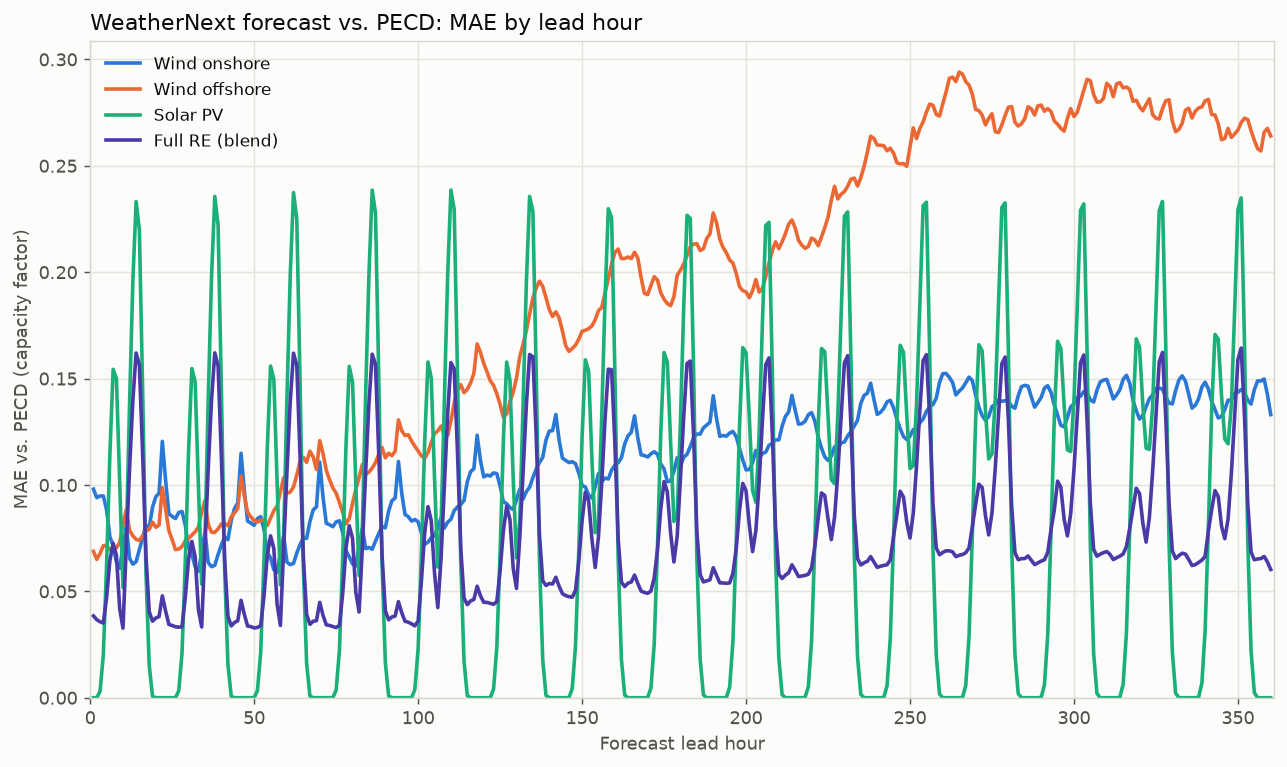

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6), dpi=130)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
for tech in ["wind_onshore", "wind_offshore", "pv", "full_re"]:
    g = curve_vs_pecd[curve_vs_pecd["technology"] == tech].sort_values("lead_hours")
    ax.plot(g["lead_hours"], g["mae"], color=COLORS[tech], linewidth=2.0, label=LABELS[tech])
ax.set_xlabel("Forecast lead hour", color=TEXT_SECONDARY)
ax.set_ylabel("MAE vs. PECD (capacity factor)", color=TEXT_SECONDARY)
ax.set_title("WeatherNext forecast vs. PECD: MAE by lead hour", color=TEXT_PRIMARY, loc="left")
ax.set_xlim(0, 361)
ax.set_ylim(0, None)
ax.grid(True, color="#e5e3dc", linewidth=0.8)
for spine in ax.spines.values():
    spine.set_color("#d8d6cd")
ax.tick_params(colors=TEXT_SECONDARY)
ax.legend(loc="upper left", frameon=False, fontsize=9.5, labelcolor=TEXT_PRIMARY)
fig.tight_layout()
plt.show()

The gap is sizeable even at the shortest lead hour (mostly PECD's own
methodology, not weather -- see section 3) and, for wind offshore in
particular, grows substantially further out.

## 2. Full RE over real time: forecast trajectories vs. PECD climatology and realized

A "spaghetti" view of the capacity-weighted Full RE blend: every
WeatherNext init's own 15-day trajectory (daily mean, one thin line per
init), against PECD's prior-years daily climatology band (10th-90th
percentile for that calendar day) and PECD's actual realized
current-year series on top. "Current year" and its date range are both
derived from what's actually in `pecd` -- not hardcoded -- so this
keeps working as more of the current year gets published upstream.

In [7]:
current_year = pd.Timestamp.now().year
daily_hist = pecd.loc[pecd.index.year < current_year, "full_re"].resample("1D").mean().to_frame("full_re")
daily_hist["month"], daily_hist["day"] = daily_hist.index.month, daily_hist.index.day
clim = daily_hist.groupby(["month", "day"])["full_re"].agg(p10=lambda s: s.quantile(0.1), p50="median", p90=lambda s: s.quantile(0.9), n="count")

realized_current_year = pecd.loc[pecd.index.year == current_year, "full_re"].resample("1D").mean()
dates_current_year = realized_current_year.index
clim_current_year = pd.DataFrame(index=dates_current_year)
clim_current_year["month"], clim_current_year["day"] = clim_current_year.index.month, clim_current_year.index.day
clim_current_year = clim_current_year.merge(clim.reset_index(), on=["month", "day"], how="left").set_index(dates_current_year)

spaghetti_source = forecast_wide.copy()
spaghetti_source["date"] = spaghetti_source["valid_time"].dt.floor("D")
spaghetti = spaghetti_source.groupby(["init_day", "date"])["full_re"].mean().reset_index()

Split into two separate charts rather than one -- each makes a different,
cleaner point on its own: climatology vs. realized asks "was 2026 a
normal winter so far", forecast vs. realized asks "did the forecasts
track what actually happened".

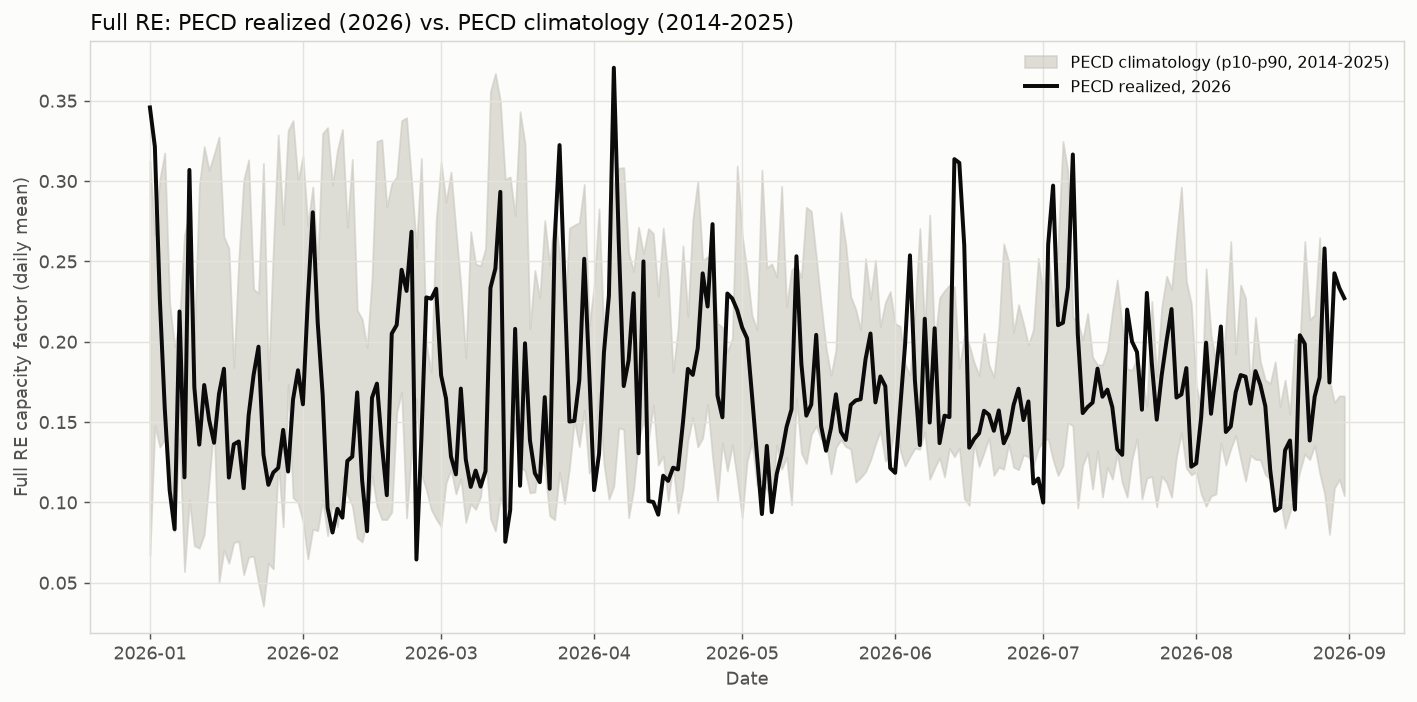

In [8]:
FORECAST_COLOR, REALIZED_COLOR, CLIM_COLOR = "#2a78d6", "#0b0b0b", "#c9c7bd"

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=130)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
ax.fill_between(clim_current_year.index, clim_current_year["p10"], clim_current_year["p90"], color=CLIM_COLOR, alpha=0.6, label=f"PECD climatology (p10-p90, {pecd.index.year.min()}-{current_year - 1})")
ax.plot(realized_current_year.index, realized_current_year.values, color=REALIZED_COLOR, linewidth=2.2, label=f"PECD realized, {current_year}")
ax.set_xlabel("Date", color=TEXT_SECONDARY)
ax.set_ylabel("Full RE capacity factor (daily mean)", color=TEXT_SECONDARY)
ax.set_title(f"Full RE: PECD realized ({current_year}) vs. PECD climatology ({pecd.index.year.min()}-{current_year - 1})", color=TEXT_PRIMARY, loc="left")
ax.grid(True, color="#e5e3dc", linewidth=0.8)
for spine in ax.spines.values():
    spine.set_color("#d8d6cd")
ax.tick_params(colors=TEXT_SECONDARY)
ax.legend(loc="upper right", frameon=False, fontsize=9, labelcolor=TEXT_PRIMARY)
fig.tight_layout()
plt.show()

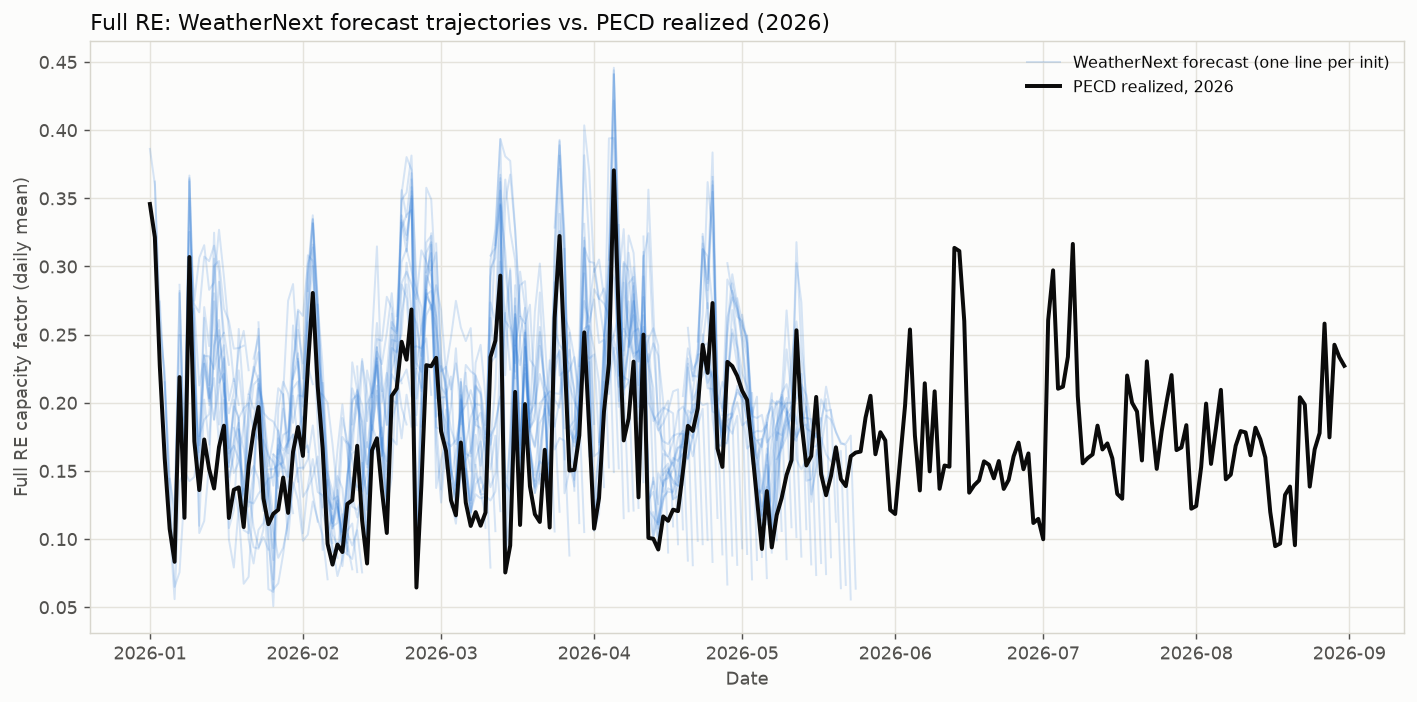

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=130)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
for i, (_, g) in enumerate(spaghetti.groupby("init_day")):
    g = g.sort_values("date")
    ax.plot(g["date"], g["full_re"], color=FORECAST_COLOR, alpha=0.18, linewidth=1.1, label="WeatherNext forecast (one line per init)" if i == 0 else None)
ax.plot(realized_current_year.index, realized_current_year.values, color=REALIZED_COLOR, linewidth=2.2, label=f"PECD realized, {current_year}")
ax.set_xlabel("Date", color=TEXT_SECONDARY)
ax.set_ylabel("Full RE capacity factor (daily mean)", color=TEXT_SECONDARY)
ax.set_title(f"Full RE: WeatherNext forecast trajectories vs. PECD realized ({current_year})", color=TEXT_PRIMARY, loc="left")
ax.grid(True, color="#e5e3dc", linewidth=0.8)
for spine in ax.spines.values():
    spine.set_color("#d8d6cd")
ax.tick_params(colors=TEXT_SECONDARY)
ax.legend(loc="upper right", frameon=False, fontsize=9, labelcolor=TEXT_PRIMARY)
fig.tight_layout()
plt.show()

## 3. At the shortest lead hour (minimal weather uncertainty): forecast vs. PECD, and vs. ERA5

Lead hour 1 is as close as WeatherNext gets to "no forecast uncertainty
left" (there is no lead hour 0 in WeatherNext's published product,
confirmed live against BigQuery). Comparing at this lead hour against
two different references isolates two different things: against ERA5
(same hub methodology on both sides) isolates the pure weather-data-
basis difference; against PECD (PECD's own methodology) mixes that same
small weather difference with PECD's own, much larger, methodology
difference.

In [10]:
era5_cf_files = sorted((HUB_DATA / "era5_capacity_factors").glob("*.parquet"))
era5_wide = pd.concat([pd.read_parquet(f) for f in era5_cf_files], ignore_index=True).set_index("valid_time").sort_index()
era5_wide["full_re"] = (era5_wide["pv"] * cap_pv + era5_wide["wind_onshore"] * cap_onshore + era5_wide["wind_offshore"] * cap_offshore) / cap_total
print(f"ERA5-fed (era5_capacity_factors_de): {era5_wide.index.min()} .. {era5_wide.index.max()} ({len(era5_wide)} rows, {len(era5_cf_files)} months)")

lead1 = forecast_wide[forecast_wide["lead_hours"] == 1].set_index("valid_time")
lead1_vs_pecd = lead1.join(pecd, rsuffix="_pecd", how="inner")
lead1_vs_era5 = lead1.join(era5_wide, rsuffix="_era5", how="inner")

ERA5-fed (era5_capacity_factors_de): 2018-10-01 00:00:00 .. 2026-07-31 23:00:00 (68664 rows, 94 months)


In [11]:
# PV dropped from here on: lead hour 1 from a 00Z init is always 01:00 --
# always night, always zero on every side of every comparison, so it's
# not an informative comparison point for solar specifically (see this
# page's intro).
LEAD1_TECHS = ["wind_onshore", "wind_offshore", "full_re"]


def scatter_grid(merged: pd.DataFrame, ref_suffix: str, ref_label: str, color: str, title: str):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), dpi=130)
    fig.patch.set_facecolor(SURFACE)
    for ax, tech in zip(axes, LEAD1_TECHS):
        ax.set_facecolor(SURFACE)
        ref, fc = merged[f"{tech}{ref_suffix}"], merged[tech]
        ax.scatter(ref, fc, s=36, color=color, alpha=0.85, edgecolor="white", linewidth=0.5, zorder=3)
        ax.plot([0, 1], [0, 1], linestyle=(0, (4, 3)), linewidth=1.3, color="#9a9890", zorder=1)
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(-0.03, 1.03)
        ax.set_aspect("equal")
        ax.set_title(LABELS[tech], color=TEXT_PRIMARY, fontsize=11.5, loc="left")
        ax.grid(True, color="#e5e3dc", linewidth=0.7, zorder=0)
        for spine in ax.spines.values():
            spine.set_color("#d8d6cd")
        ax.tick_params(colors=TEXT_SECONDARY, labelsize=8.5)
    fig.suptitle(title, color=TEXT_PRIMARY, fontsize=13, x=0.02, ha="left", y=0.99)
    fig.supxlabel(f"{ref_label} capacity factor", color=TEXT_SECONDARY, fontsize=10.5)
    fig.supylabel("WeatherNext forecast, 1h lead", color=TEXT_SECONDARY, fontsize=10.5)
    fig.tight_layout(rect=[0.02, 0.02, 1, 0.9])
    plt.show()


def timeseries_grid(merged: pd.DataFrame, ref_suffix: str, ref_label: str, ref_color: str, title: str):
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), dpi=130, sharex=True)
    fig.patch.set_facecolor(SURFACE)
    for ax, tech in zip(axes, LEAD1_TECHS):
        ax.set_facecolor(SURFACE)
        ax.plot(merged.index, merged[tech], color="#4a3aa7", linewidth=1.6, label="WeatherNext (1h lead)", zorder=3)
        ax.plot(merged.index, merged[f"{tech}{ref_suffix}"], color=ref_color, linewidth=1.6, label=ref_label, zorder=2)
        ax.set_title(LABELS[tech], color=TEXT_PRIMARY, fontsize=11.5, loc="left")
        ax.grid(True, color="#e5e3dc", linewidth=0.7)
        for spine in ax.spines.values():
            spine.set_color("#d8d6cd")
        ax.tick_params(colors=TEXT_SECONDARY, labelsize=8.5)
    axes[0].legend(loc="upper right", frameon=False, fontsize=8.5, labelcolor=TEXT_PRIMARY)
    fig.suptitle(title, color=TEXT_PRIMARY, fontsize=13, x=0.02, ha="left", y=0.995)
    fig.supylabel("Capacity factor", color=TEXT_SECONDARY, fontsize=10.5)
    fig.tight_layout(rect=[0.02, 0.0, 1, 0.96])
    plt.show()

### 3a. Same methodology (ERA5) -- isolates the pure weather-data-basis gap

Forecast and reference go through the identical conversion code here;
the only thing that can differ is the weather input itself -- WeatherNext's
own 1h-lead analysis/initial-condition field vs. ERA5's reanalysis.
Whatever gap remains is attributable to that (and possibly a labeling
convention, e.g. the kind of 1h accumulation/timestamp offset PECD's own
solar product is independently known to have -- not yet checked for
WeatherNext itself).

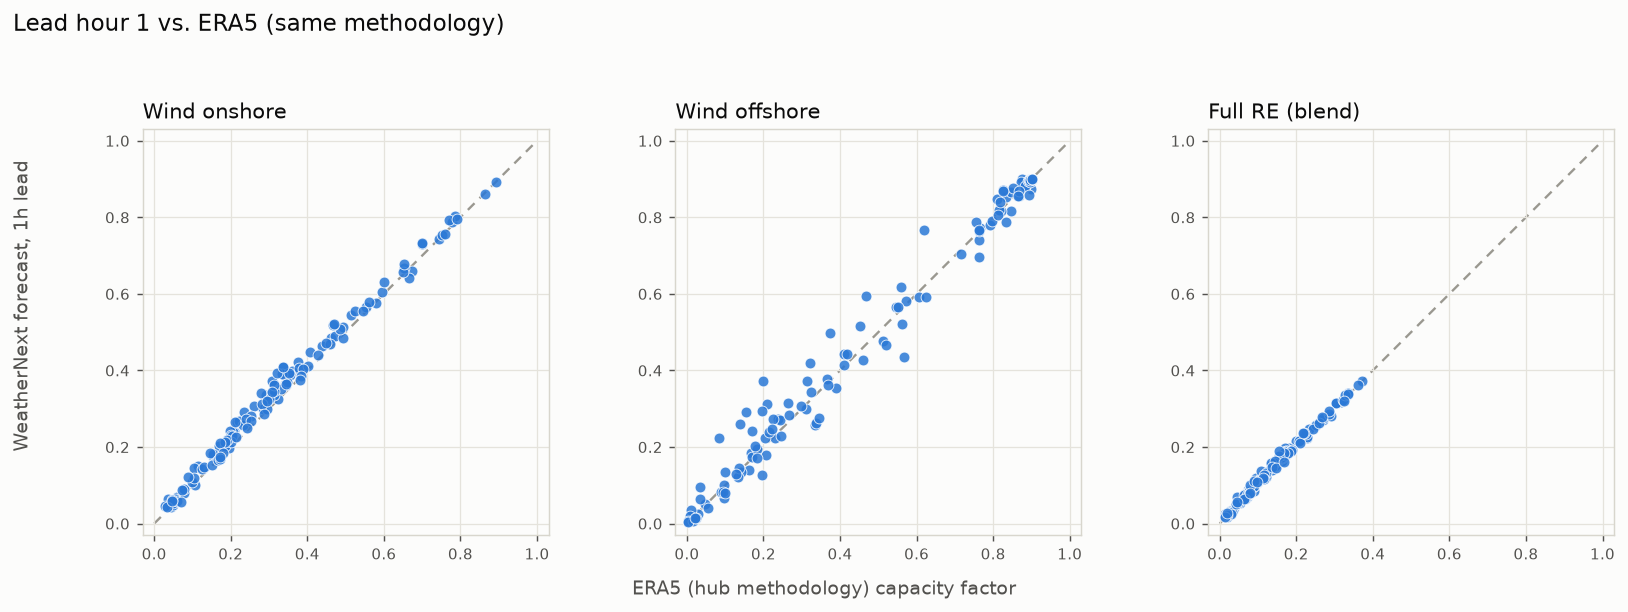

In [12]:
scatter_grid(lead1_vs_era5, "_era5", "ERA5 (hub methodology)", "#2a78d6", "Lead hour 1 vs. ERA5 (same methodology)")

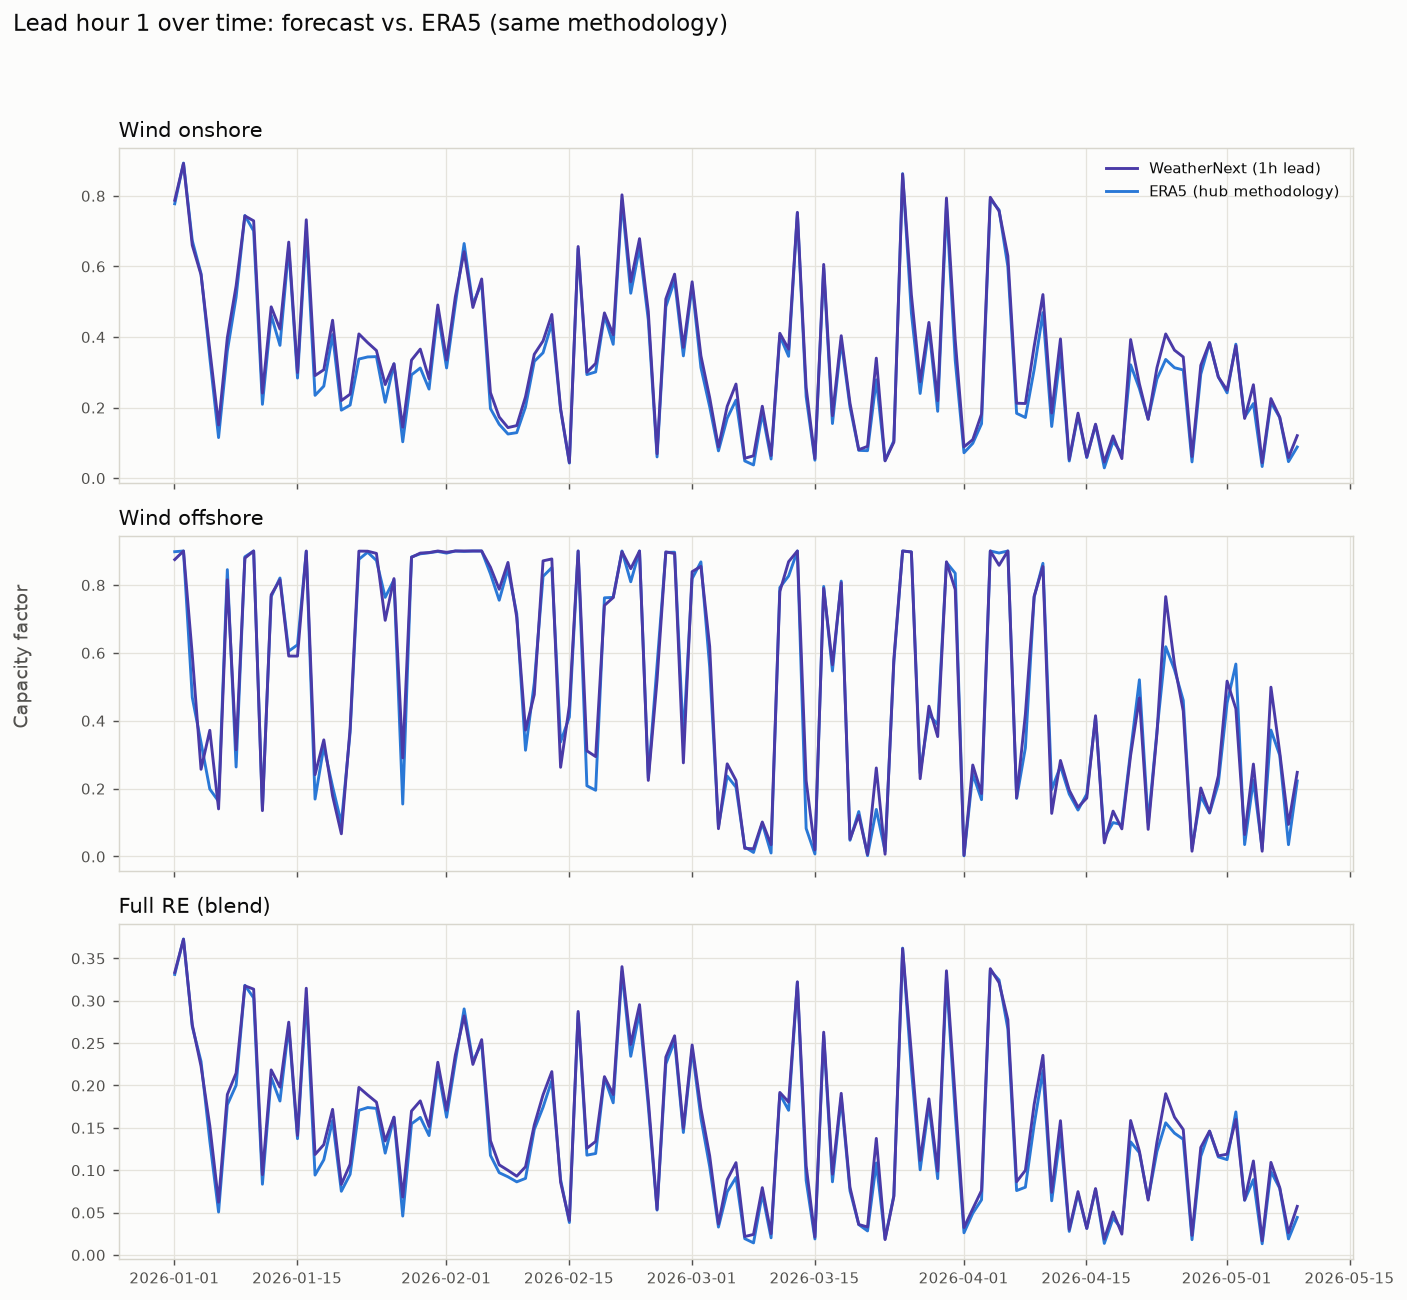

In [13]:
timeseries_grid(lead1_vs_era5, "_era5", "ERA5 (hub methodology)", "#2a78d6", "Lead hour 1 over time: forecast vs. ERA5 (same methodology)")

### 3b. Different methodology (PECD) -- weather-basis gap + methodology gap combined

Same forecast-side values as above; the reference side now goes through
PECD's own, different conversion methodology instead of this hub's. Since
3a already showed the pure weather-basis gap is small, most of whatever
additional gap shows up here is attributable to the methodology
difference, not the weather.

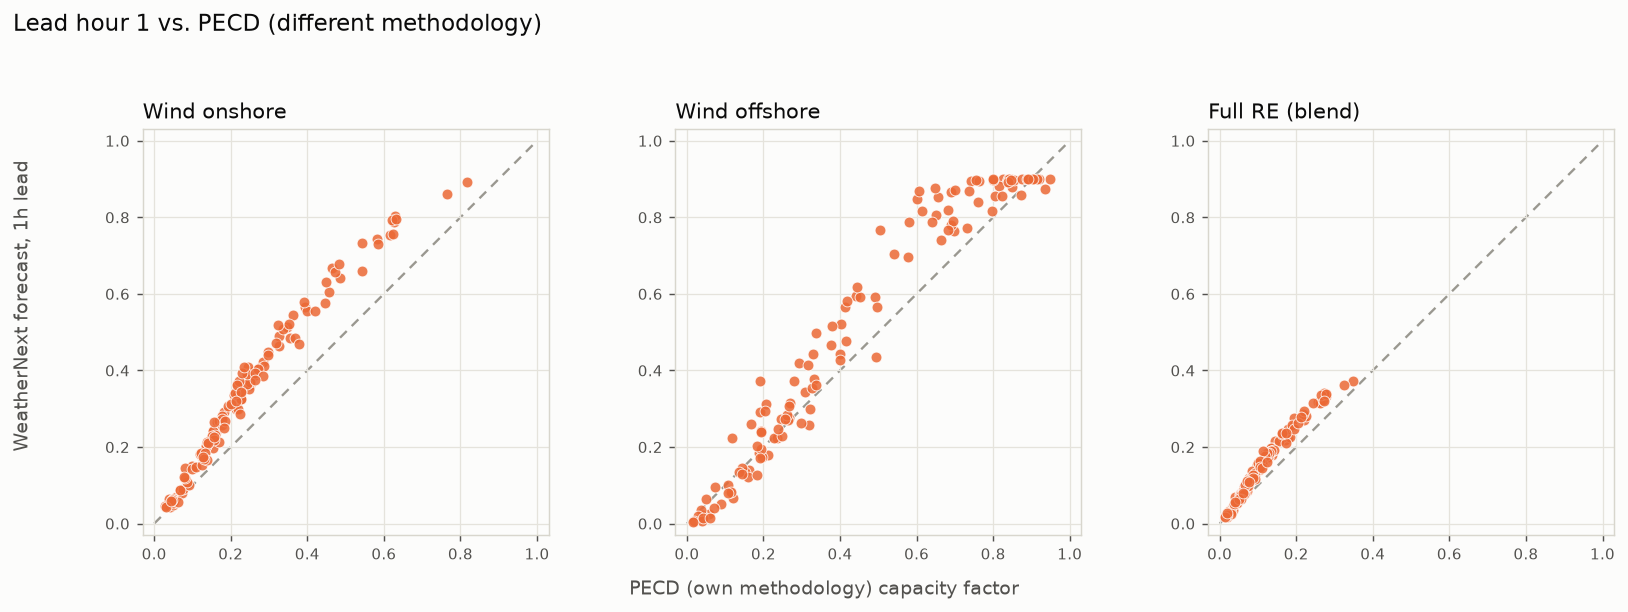

In [14]:
scatter_grid(lead1_vs_pecd, "_pecd", "PECD (own methodology)", "#eb6834", "Lead hour 1 vs. PECD (different methodology)")

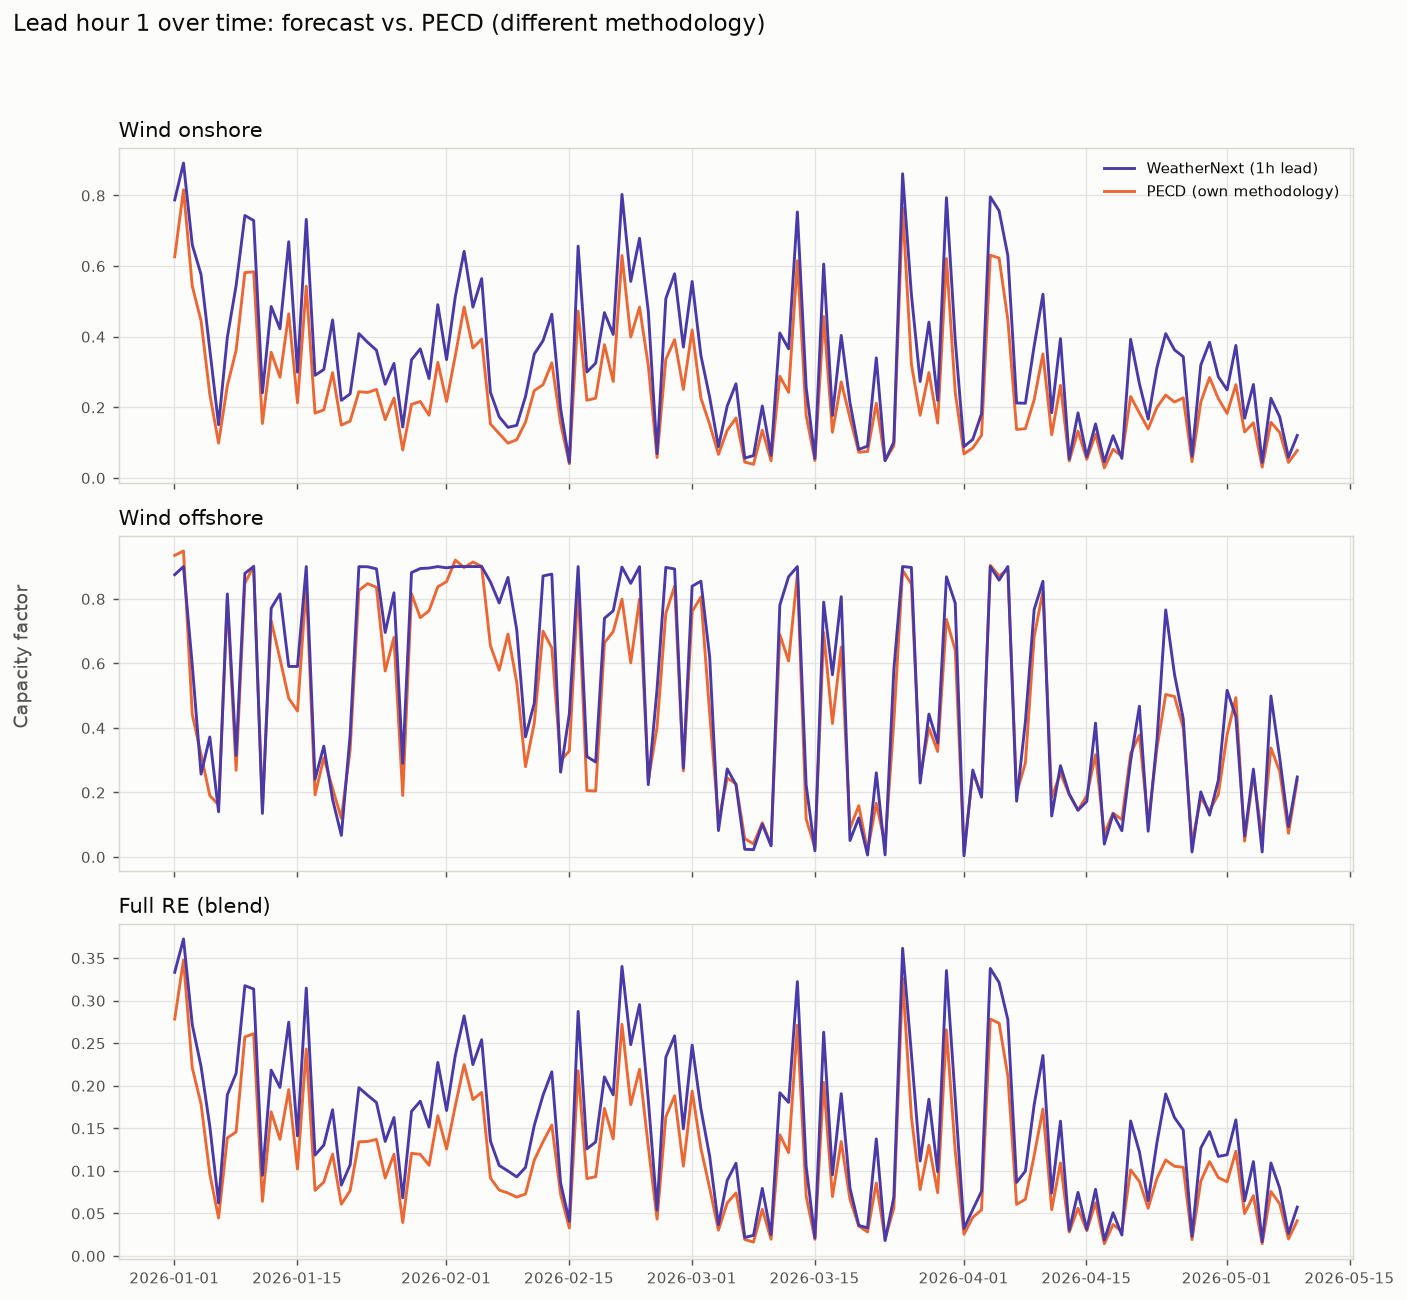

In [15]:
timeseries_grid(lead1_vs_pecd, "_pecd", "PECD (own methodology)", "#eb6834", "Lead hour 1 over time: forecast vs. PECD (different methodology)")

## 4. Known weather, same methodology, across the full lead-hour range (work in progress)

The ERA5-based MAE-by-lead-hour curve isolates pure weather-forecast
error from methodology difference -- but exactly how to frame that
alongside the PECD curve above (same chart? separately, with the gap
between them as its own quantity?) is still being worked out; shown
here as its own chart for now, not yet combined into one message with
section 1.

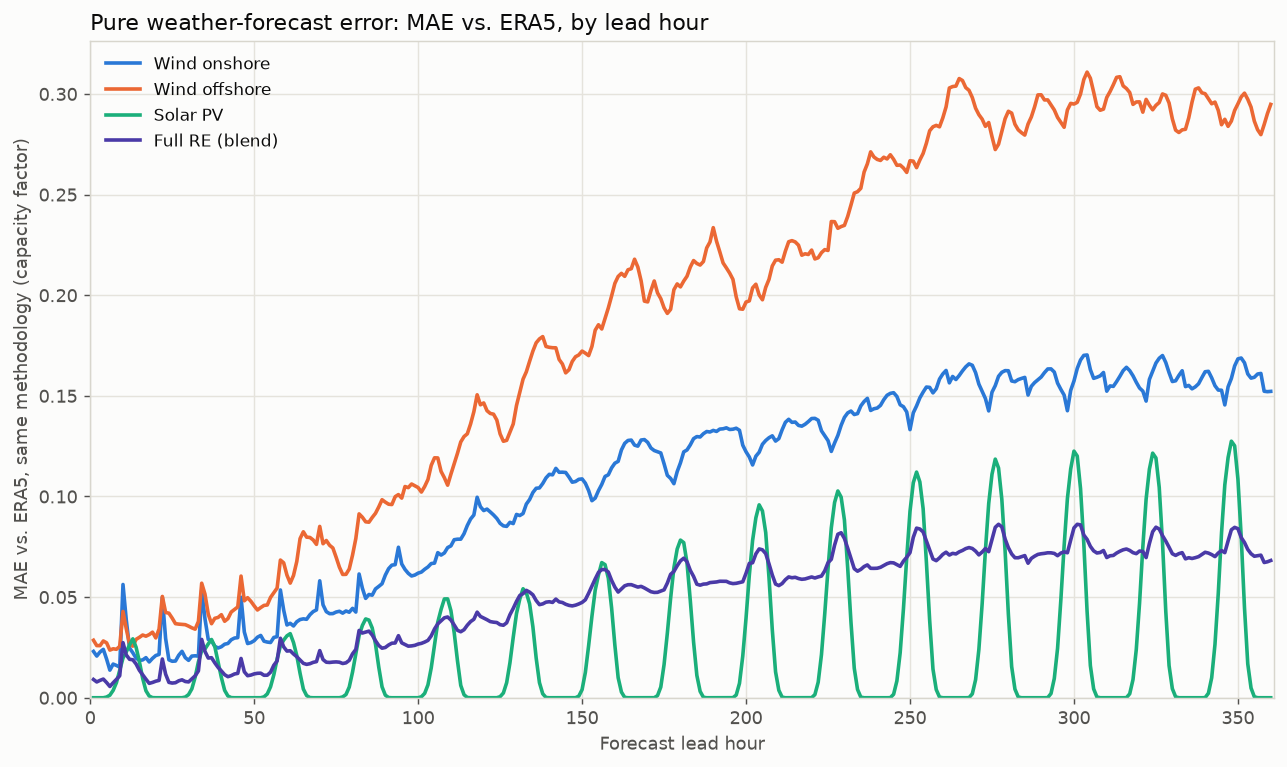

In [16]:
curve_vs_era5 = mae_by_lead_hour(forecast_wide, era5_wide, "ERA5")

fig, ax = plt.subplots(figsize=(10, 6), dpi=130)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
for tech in ["wind_onshore", "wind_offshore", "pv", "full_re"]:
    g = curve_vs_era5[curve_vs_era5["technology"] == tech].sort_values("lead_hours")
    ax.plot(g["lead_hours"], g["mae"], color=COLORS[tech], linewidth=2.0, label=LABELS[tech])
ax.set_xlabel("Forecast lead hour", color=TEXT_SECONDARY)
ax.set_ylabel("MAE vs. ERA5, same methodology (capacity factor)", color=TEXT_SECONDARY)
ax.set_title("Pure weather-forecast error: MAE vs. ERA5, by lead hour", color=TEXT_PRIMARY, loc="left")
ax.set_xlim(0, 361)
ax.set_ylim(0, None)
ax.grid(True, color="#e5e3dc", linewidth=0.8)
for spine in ax.spines.values():
    spine.set_color("#d8d6cd")
ax.tick_params(colors=TEXT_SECONDARY)
ax.legend(loc="upper left", frameon=False, fontsize=9.5, labelcolor=TEXT_PRIMARY)
fig.tight_layout()
plt.show()

At short lead times this is much smaller than the PECD-referenced curve
in section 1 -- confirming that gap is mostly methodology, not weather.
At the longest lead times, the pure weather error for wind offshore
actually overtakes the (roughly constant) PECD methodology gap -- i.e.
forecast-weather uncertainty, not methodology, becomes the dominant
error source far out. Germany's fleet-wide numbers only; not yet
broken out by how much of the long-lead growth is forecast-model skill
vs. this hub's own bias-correction/turbine assumptions degrading
further from WeatherNext's native resolution -- a natural next
iteration.